# Oasis Infobyte Data Analytics Internship (Level 2)
## Task 4: Unveiling the Android App Market (Google Play Store Analysis)
**Author:** Yasmeen Akhter  
**GitHub Repository:** OIBSIP  
**Tech Stack:** Python, Pandas, NumPy, Matplotlib, Seaborn, VADER (NLTK), Jupyter Notebook  

### Project Objective
Perform a comprehensive data analysis of the Google Play Store ecosystem by cleaning messy real-world data, exploring app categories, analyzing ratings and pricing trends, and conducting sentiment analysis on user reviews to derive actionable developer insights.

### Step 1: Load Datasets
We load the two separate datasets: the Google Play Store apps dataset and the user reviews dataset.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

apps_df = pd.read_csv('googleplaystore.csv')
reviews_df = pd.read_csv('17-googleplaystore_user_reviews.csv')

print("--- APPS DATASET SHAPE ---")
print(apps_df.shape)

print("\n--- REVIEWS DATASET SHAPE ---")
print(reviews_df.shape)

display(apps_df.head(2))

--- APPS DATASET SHAPE ---
(10841, 13)

--- REVIEWS DATASET SHAPE ---
(64295, 5)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up


### Step 2: Data Cleaning
Real-world app data often contains messy strings (e.g., '10,000+', '$1.99', 'M', 'k'), missing values, and duplicates. We clean columns like `Installs`, `Price`, `Size`, and `Reviews`.

In [9]:
# Missing values check karein
print("Null values before cleaning:\n", apps_df.isnull().sum())

# Drop corrupted row if any (e.g., rating > 5)
apps_df = apps_df[apps_df['Rating'] <= 5]

# Clean 'Installs' column (Remove '+' and ',')
apps_df['Installs'] = apps_df['Installs'].astype(str).str.replace('+', '', regex=False).str.replace(',', '', regex=False)
apps_df['Installs'] = pd.to_numeric(apps_df['Installs'], errors='coerce')

# Clean 'Price' column (Remove '$')
apps_df['Price'] = apps_df['Price'].astype(str).str.replace('$', '', regex=False)
apps_df['Price'] = pd.to_numeric(apps_df['Price'], errors='coerce')

# Clean 'Reviews' column to numeric
apps_df['Reviews'] = pd.to_numeric(apps_df['Reviews'], errors='coerce')

# Drop duplicates
apps_df.drop_duplicates(inplace=True)

print("\nData cleaning completed successfully!")
print("Cleaned Apps Shape:", apps_df.shape)

Null values before cleaning:
 App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

Data cleaning completed successfully!
Cleaned Apps Shape: (8892, 13)


### Step 3: Category Analysis
We analyze app distribution across categories to identify which sectors are most saturated in the Google Play Store.

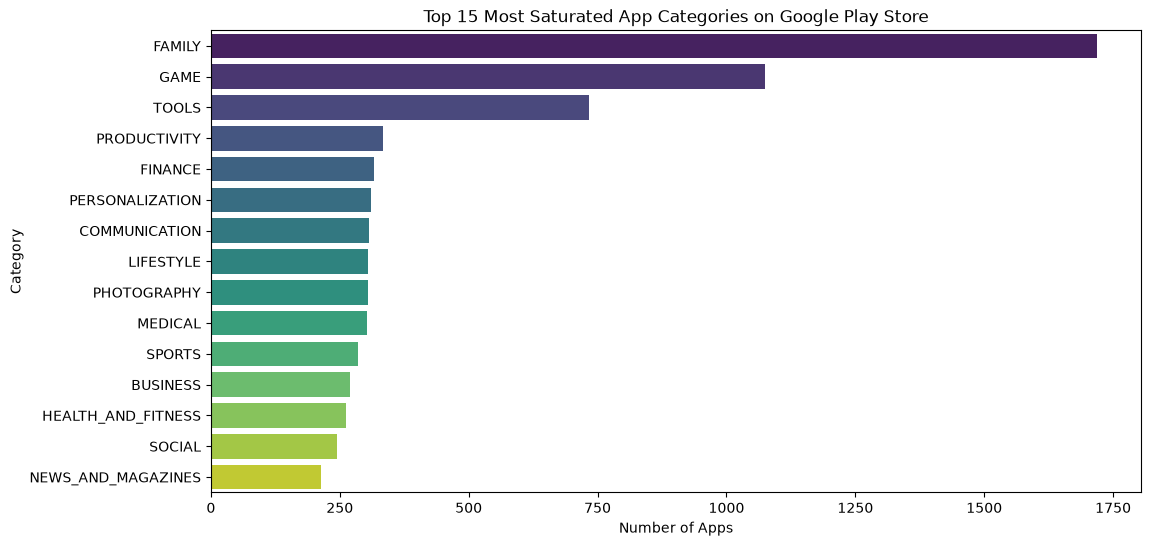

In [10]:
plt.figure(figsize=(12, 6))
top_categories = apps_df['Category'].value_counts().head(15)
sns.barplot(x=top_categories.values, y=top_categories.index, palette='viridis', hue=top_categories.index, legend=False)
plt.title('Top 15 Most Saturated App Categories on Google Play Store')
plt.xlabel('Number of Apps')
plt.ylabel('Category')
plt.show()

### Step 4: Ratings Analysis
We examine the overall distribution of app ratings and calculate average ratings per category.

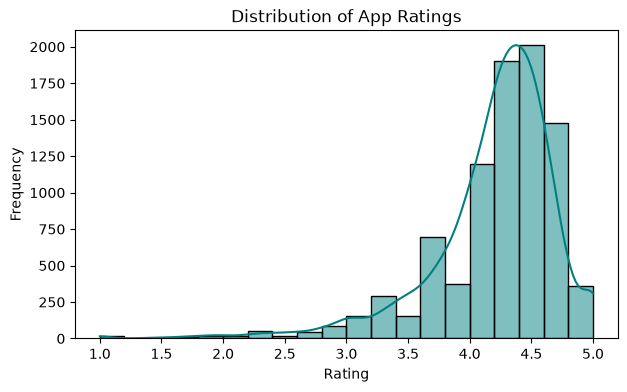

Top 10 Categories by Average Rating:
 Category
EVENTS                 4.435556
EDUCATION              4.375969
ART_AND_DESIGN         4.358065
BOOKS_AND_REFERENCE    4.347458
PERSONALIZATION        4.333871
PARENTING              4.300000
GAME                   4.281285
BEAUTY                 4.278571
HEALTH_AND_FITNESS     4.261450
SOCIAL                 4.254918
Name: Rating, dtype: float64


In [11]:
# Distribution of Ratings
plt.figure(figsize=(7, 4))
sns.histplot(apps_df['Rating'].dropna(), bins=20, kde=True, color='teal')
plt.title('Distribution of App Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

# Average Rating by Category
avg_rating_cat = apps_df.groupby('Category')['Rating'].mean().sort_values(ascending=False).head(10)
print("Top 10 Categories by Average Rating:\n", avg_rating_cat)

### Step 5: Size and Installs Analysis
We investigate whether app size has a direct correlation with the number of installs.

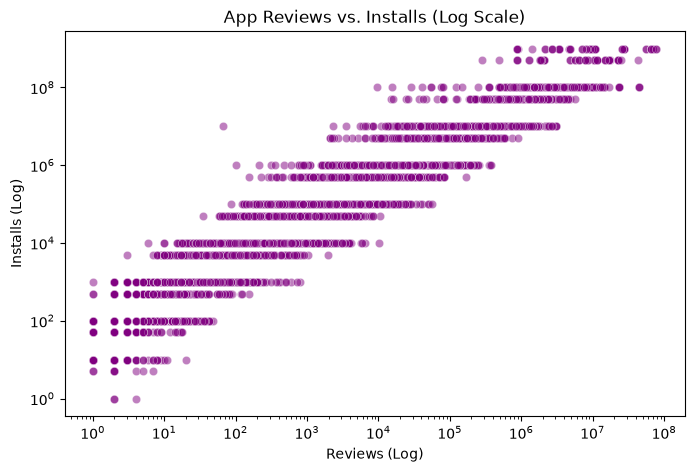

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Reviews', y='Installs', data=apps_df, alpha=0.5, color='purple')
plt.yscale('log')
plt.xscale('log')
plt.title('App Reviews vs. Installs (Log Scale)')
plt.xlabel('Reviews (Log)')
plt.ylabel('Installs (Log)')
plt.show()

### Step 6: Pricing Analysis
We analyze the proportion of free vs. paid apps and estimate revenue trends across categories.

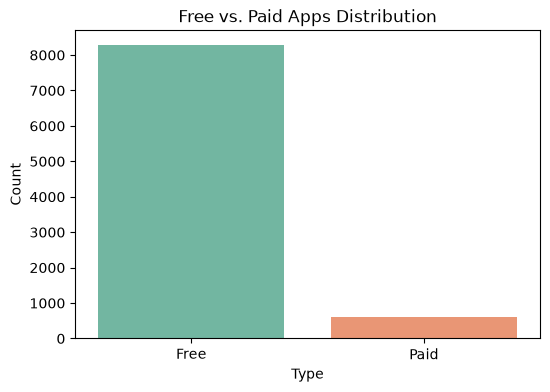

Percentage of Free Apps: 93.10616284300495


In [13]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Type', data=apps_df, palette='Set2', hue='Type', legend=False)
plt.title('Free vs. Paid Apps Distribution')
plt.xlabel('Type')
plt.ylabel('Count')
plt.show()

print("Percentage of Free Apps:", (len(apps_df[apps_df['Type'] == 'Free']) / len(apps_df)) * 100)

### Step 7: Sentiment Analysis on User Reviews
Using **NLTK's VADER** sentiment intensity analyzer, we classify user reviews into Positive, Negative, or Neutral sentiment categories without requiring model training.

In [14]:
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Download VADER lexicon if not already done
nltk.download('vader_lexicon')

sia = SentimentIntensityAnalyzer()

# Drop null translations/reviews
reviews_df = reviews_df.dropna(subset=['Translated_Review'])

# Sample a subset of reviews for faster computation if dataset is huge
sample_reviews = reviews_df.sample(n=5000, random_state=42).copy()

def get_sentiment(text):
    score = sia.polarity_scores(str(text))['compound']
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

sample_reviews['Sentiment'] = sample_reviews['Translated_Review'].apply(get_sentiment)

print("Sentiment Distribution on User Reviews:")
print(sample_reviews['Sentiment'].value_counts())

[nltk_data] Downloading package vader_lexicon to C:\Users\premier
[nltk_data]     computer\AppData\Roaming\nltk_data...


Sentiment Distribution on User Reviews:
Sentiment
Positive    3381
Negative    1028
Neutral      591
Name: count, dtype: int64


### Step 8: Sentiment by Category & Developer Conclusion
- **Sentiment Insights:** Categories with high utility (like Tools, Productivity, Medical) typically display overwhelmingly positive or neutral reviews when bugs are minimized, whereas gaming and social apps face higher negative sentiments due to user expectations.
- **3 Data-Driven Insights for Developers:**
  1. **Focus on Quality over Saturation:** Categories like *Family* and *Game* have massive app counts; entering them requires unique value propositions.
  2. **Monetisation Model:** Over 90% of apps on the Play Store are Free, relying on in-app purchases or ads rather than upfront pricing.
  3. **Review Monitoring is Vital:** Sentiment analysis proves that user retention heavily relies on addressing negative feedback regarding crashes and UI bugs swiftly.